<center><h1>Zheng_Yiyi_HW7</h1></center>

Name: yiyi zheng
<br>
Github Username: yiyizheng111
<br>
USC ID: 7092417109

## 1. Multi-class and Multi-Label Classification Using Support Vector Machines

Import packages

In [1]:

# Import packages

from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


### (a) Download the Anuran Calls (MFCCs) Data Set

In [3]:


# Question 1(a): Load the Anuran Calls dataset

data_path = Path("Anuran Calls (MFCCs)") / "Frogs_MFCCs.csv"

frog_df = pd.read_csv(data_path)

print("Dataset shape:", frog_df.shape)

print("\nFirst five rows:")
display(frog_df.head())

print("\nColumn names:")
print(frog_df.columns.tolist())

print("\nMissing values:", frog_df.isna().sum().sum())


Dataset shape: (7195, 26)

First five rows:


,MFCCs_ 1,MFCCs_ 2,MFCCs_ 3,MFCCs_ 4,MFCCs_ 5,MFCCs_ 6,MFCCs_ 7,MFCCs_ 8,MFCCs_ 9,MFCCs_10,...,MFCCs_17,MFCCs_18,MFCCs_19,MFCCs_20,MFCCs_21,MFCCs_22,Family,Genus,Species,RecordID
0,1.0,0.152936,-0.105586,0.200722,0.317201,0.260764,0.100945,-0.150063,-0.171128,0.124676,...,-0.108351,-0.077623,-0.009568,0.057684,0.118680,0.014038,Leptodactylidae,Adenomera,AdenomeraAndre,1
1,1.0,0.171534,-0.098975,0.268425,0.338672,0.268353,0.060835,-0.222475,-0.207693,0.170883,...,-0.090974,-0.056510,-0.035303,0.020140,0.082263,0.029056,Leptodactylidae,Adenomera,AdenomeraAndre,1
2,1.0,0.152317,-0.082973,0.287128,0.276014,0.189867,0.008714,-0.242234,-0.219153,0.232538,...,-0.050691,-0.023590,-0.066722,-0.025083,0.099108,0.077162,Leptodactylidae,Adenomera,AdenomeraAndre,1
3,1.0,0.224392,0.118985,0.329432,0.372088,0.361005,0.015501,-0.194347,-0.098181,0.270375,...,-0.136009,-0.177037,-0.130498,-0.054766,-0.018691,0.023954,Leptodactylidae,Adenomera,AdenomeraAndre,1
4,1.0,0.087817,-0.068345,0.306967,0.330923,0.249144,0.006884,-0.265423,-0.172700,0.266434,...,-0.048885,-0.053074,-0.088550,-0.031346,0.108610,0.079244,Leptodactylidae,Adenomera,AdenomeraAndre,1



Column names:
['MFCCs_ 1', 'MFCCs_ 2', 'MFCCs_ 3', 'MFCCs_ 4', 'MFCCs_ 5', 'MFCCs_ 6', 'MFCCs_ 7', 'MFCCs_ 8', 'MFCCs_ 9', 'MFCCs_10', 'MFCCs_11', 'MFCCs_12', 'MFCCs_13', 'MFCCs_14', 'MFCCs_15', 'MFCCs_16', 'MFCCs_17', 'MFCCs_18', 'MFCCs_19', 'MFCCs_20', 'MFCCs_21', 'MFCCs_22', 'Family', 'Genus', 'Species', 'RecordID']

Missing values: 0


In [4]:

# Question 1(a): Split the data into training and test sets

from sklearn.model_selection import train_test_split

# Select the 22 MFCC features
feature_cols = [col for col in frog_df.columns
                if col.startswith("MFCCs_")]

X = frog_df[feature_cols]

# Select the three labels
y = frog_df[["Family", "Genus", "Species"]]

# Randomly split 70% training and 30% testing
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    train_size=0.7,
    random_state=42
)

print("Full dataset shape:", frog_df.shape)
print("Training features:", X_train.shape)
print("Test features:", X_test.shape)
print("Training labels:", y_train.shape)
print("Test labels:", y_test.shape)

print("\nNumber of classes in each label:")
print(y.nunique())


Full dataset shape: (7195, 26)
Training features: (5036, 22)
Test features: (2159, 22)
Training labels: (5036, 3)
Test labels: (2159, 3)

Number of classes in each label:
Family      4
Genus       8
Species    10
dtype: int64


I loaded the Anuran Calls (MFCCs) dataset, which contains 7,195 observations and 22 MFCC features.

The dataset has three labels: Family, Genus, and Species. They contain 4, 8, and 10 classes, respectively.

I randomly selected 70% of the observations for training and the remaining 30% for testing using random_state=42.

The training set contains 5,036 observations, and the test set contains 2,159 observations. There are no missing values in the dataset.

### (b) Train a classifier for each label

#### (i) Research



**Exact Match:** An observation is counted as correct only when all three labels (Family, Genus, and Species) are predicted correctly.

**Hamming Score:** It measures the proportion of individual labels predicted correctly.

**Hamming Loss:** It measures the proportion of individual labels predicted incorrectly.

For this problem, Hamming Score = 1 - Hamming Loss.

Exact Match is stricter because all three labels must be correct at the same time. I will use these metrics to evaluate the classification models.

In [41]:

# Question 1(b)(i): Evaluation metrics

def evaluate_labels(y_true, y_pred):
    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)

    correct = (y_true == y_pred)

    exact_match = correct.all(axis=1).mean()
    hamming_score = correct.mean()
    hamming_loss = 1 - hamming_score

    print("Exact Match:", round(exact_match, 4))
    print("Hamming Score:", round(hamming_score, 4))
    print("Hamming Loss:", round(hamming_loss, 4))


#### (ii) Train a SVM for each of the labels

In [9]:

# Question 1(b)(ii): Gaussian SVM for Family

from sklearn.svm import SVC
from sklearn.multiclass import OneVsRestClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV, StratifiedKFold

# Build the Gaussian SVM pipeline
family_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("svm", OneVsRestClassifier(SVC(kernel="rbf")))
])

# Parameters to test
param_grid = {
    "svm__estimator__C": [0.1, 1, 10],
    "svm__estimator__gamma": [0.01, 0.1, 1]
}

# 10-fold cross-validation
cv = StratifiedKFold(
    n_splits=10,
    shuffle=True,
    random_state=42
)

# Find the best parameters
family_search = GridSearchCV(
    family_pipeline,
    param_grid=param_grid,
    cv=cv,
    scoring="accuracy",
    n_jobs=-1
)

# Train the Family classifier
family_search.fit(X_train, y_train["Family"])

print("Family Gaussian SVM Results:")
print("Best C:", family_search.best_params_["svm__estimator__C"])
print("Best gamma:", family_search.best_params_["svm__estimator__gamma"])
print("Best CV Accuracy:", family_search.best_score_)


Family Gaussian SVM Results:
Best C: 10
Best gamma: 0.1
Best CV Accuracy: 0.9904683013032912


In [10]:

# Question 1(b)(ii): Fine search for Family Gaussian SVM

fine_param_grid = {
    "svm__estimator__C": [10, 30, 100],
    "svm__estimator__gamma": [0.03, 0.1, 0.3]
}

family_fine_search = GridSearchCV(
    family_pipeline,
    param_grid=fine_param_grid,
    cv=cv,
    scoring="accuracy",
    n_jobs=-1
)

family_fine_search.fit(X_train, y_train["Family"])

print("Final Family Gaussian SVM Results:")
print("Best C:", family_fine_search.best_params_["svm__estimator__C"])
print("Best gamma:", family_fine_search.best_params_["svm__estimator__gamma"])
print("Best CV Accuracy:", family_fine_search.best_score_)


Final Family Gaussian SVM Results:
Best C: 30
Best gamma: 0.03
Best CV Accuracy: 0.9924524282874183


In [11]:

# Question 1(b)(ii): Test the Family Gaussian SVM

from sklearn.metrics import accuracy_score

family_model = family_fine_search.best_estimator_

# Predict Family labels on the test set
family_pred = family_model.predict(X_test)

# Calculate test accuracy
family_test_acc = accuracy_score(y_test["Family"], family_pred)

print("Family Test Accuracy:", round(family_test_acc, 4))
print("Correct predictions:", (y_test["Family"] == family_pred).sum())
print("Total test observations:", len(y_test))


Family Test Accuracy: 0.9931
Correct predictions: 2144
Total test observations: 2159


In [12]:

# Question 1(b)(ii): Gaussian SVM for Genus

genus_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("svm", OneVsRestClassifier(SVC(kernel="rbf")))
])

genus_param_grid = {
    "svm__estimator__C": [0.1, 1, 10, 30, 100],
    "svm__estimator__gamma": [0.01, 0.03, 0.1, 0.3, 1]
}

genus_search = GridSearchCV(
    genus_pipeline,
    param_grid=genus_param_grid,
    cv=cv,
    scoring="accuracy",
    n_jobs=-1
)

genus_search.fit(X_train, y_train["Genus"])

print("Genus Gaussian SVM Results:")
print("Best C:", genus_search.best_params_["svm__estimator__C"])
print("Best gamma:", genus_search.best_params_["svm__estimator__gamma"])
print("Best CV Accuracy:", genus_search.best_score_)


Genus Gaussian SVM Results:
Best C: 10
Best gamma: 0.03
Best CV Accuracy: 0.9904675123860013


In [13]:

# Question 1(b)(ii): Test the Genus Gaussian SVM

genus_model = genus_search.best_estimator_

# Predict Genus labels on the test set
genus_pred = genus_model.predict(X_test)

# Calculate test accuracy
genus_test_acc = accuracy_score(y_test["Genus"], genus_pred)

print("Genus Test Accuracy:", round(genus_test_acc, 4))
print("Correct predictions:", (y_test["Genus"] == genus_pred).sum())
print("Total test observations:", len(y_test))


Genus Test Accuracy: 0.9884
Correct predictions: 2134
Total test observations: 2159


In [14]:

# Question 1(b)(ii): Gaussian SVM for Species

species_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("svm", OneVsRestClassifier(SVC(kernel="rbf")))
])

species_param_grid = {
    "svm__estimator__C": [0.1, 1, 10, 30, 100],
    "svm__estimator__gamma": [0.01, 0.03, 0.1, 0.3, 1]
}

species_search = GridSearchCV(
    species_pipeline,
    param_grid=species_param_grid,
    cv=cv,
    scoring="accuracy",
    n_jobs=-1
)

species_search.fit(X_train, y_train["Species"])

print("Species Gaussian SVM Results:")
print("Best C:", species_search.best_params_["svm__estimator__C"])
print("Best gamma:", species_search.best_params_["svm__estimator__gamma"])
print("Best CV Accuracy:", species_search.best_score_)


Species Gaussian SVM Results:
Best C: 10
Best gamma: 0.03
Best CV Accuracy: 0.990471062513806


In [15]:

# Question 1(b)(ii): Test the Species Gaussian SVM

species_model = species_search.best_estimator_

# Predict Species labels on the test set
species_pred = species_model.predict(X_test)

# Calculate test accuracy
species_test_acc = accuracy_score(y_test["Species"], species_pred)

print("Species Test Accuracy:", round(species_test_acc, 4))
print("Correct predictions:", (y_test["Species"] == species_pred).sum())
print("Total test observations:", len(y_test))


Species Test Accuracy: 0.9884
Correct predictions: 2134
Total test observations: 2159


In [16]:

# Question 1(b)(ii): Evaluate Gaussian SVM

# Combine predictions for all three labels
gaussian_pred = np.column_stack([
    family_pred,
    genus_pred,
    species_pred
])

print("Gaussian SVM - Test Results:")
evaluate_labels(y_test, gaussian_pred)


Gaussian SVM - Test Results:
Exact Match: 0.9861
Hamming Score: 0.99
Hamming Loss: 0.01




I trained three Gaussian kernel SVM classifiers to predict Family, Genus, and Species separately. I used One-vs-Rest classification and standardized the features using StandardScaler.

I used 10-fold cross-validation to select the best C and gamma parameters for each classifier.

The results are:

| Label | Best C | Best gamma | CV Accuracy | Test Accuracy |
|---|---:|---:|---:|---:|
| Family | 30 | 0.03 | 99.25% | 99.31% |
| Genus | 10 | 0.03 | 99.05% | 98.84% |
| Species | 10 | 0.03 | 99.05% | 98.84% |

The overall multi-label test results are:

- Exact Match: 0.9861
- Hamming Score: 0.9900
- Hamming Loss: 0.0100

The Gaussian SVM classifiers performed well on all three labels. The high exact match score shows that most test observations had all three labels predicted correctly.


#### (iii) Repeat 1(b)ii with L1-penalized SVMs

In [17]:

# Question 1(b)(iii): L1-Penalized SVM for Family

from sklearn.svm import LinearSVC

# Build the L1-penalized SVM pipeline
l1_family_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("svm", OneVsRestClassifier(
        LinearSVC(
            penalty="l1",
            dual=False,
            max_iter=20000,
            random_state=42
        )
    ))
])

# Parameters to test
l1_param_grid = {
    "svm__estimator__C": [0.001, 0.01, 0.1, 1, 10]
}

# 10-fold cross-validation
l1_family_search = GridSearchCV(
    l1_family_pipeline,
    param_grid=l1_param_grid,
    cv=cv,
    scoring="accuracy",
    n_jobs=-1
)

l1_family_search.fit(X_train, y_train["Family"])

print("Family L1-SVM Results:")
print("Best C:", l1_family_search.best_params_["svm__estimator__C"])
print("Best CV Accuracy:", l1_family_search.best_score_)


Family L1-SVM Results:
Best C: 10
Best CV Accuracy: 0.9412229006910916


In [18]:

# Question 1(b)(iii): Fine search for Family L1-SVM

l1_fine_param_grid = {
    "svm__estimator__C": [1, 10, 30, 100]
}

l1_family_fine_search = GridSearchCV(
    l1_family_pipeline,
    param_grid=l1_fine_param_grid,
    cv=cv,
    scoring="accuracy",
    n_jobs=-1
)

l1_family_fine_search.fit(X_train, y_train["Family"])

print("Final Family L1-SVM Results:")
print("Best C:", l1_family_fine_search.best_params_["svm__estimator__C"])
print("Best CV Accuracy:", l1_family_fine_search.best_score_)


Final Family L1-SVM Results:
Best C: 10
Best CV Accuracy: 0.9412229006910916


In [19]:

# Question 1(b)(iii): Test the Family L1-SVM

l1_family_model = l1_family_fine_search.best_estimator_

# Predict Family labels
l1_family_pred = l1_family_model.predict(X_test)

# Calculate test accuracy
l1_family_test_acc = accuracy_score(
    y_test["Family"], l1_family_pred
)

print("Family L1-SVM Test Accuracy:", round(l1_family_test_acc, 4))
print("Correct predictions:", (y_test["Family"] == l1_family_pred).sum())
print("Total test observations:", len(y_test))


Family L1-SVM Test Accuracy: 0.9282
Correct predictions: 2004
Total test observations: 2159


In [20]:

# Question 1(b)(iii): L1-Penalized SVM for Genus

l1_genus_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("svm", OneVsRestClassifier(
        LinearSVC(
            penalty="l1",
            dual=False,
            max_iter=20000,
            random_state=42
        )
    ))
])

# Parameters to test
l1_genus_param_grid = {
    "svm__estimator__C": [0.001, 0.01, 0.1, 1, 10, 30, 100]
}

# 10-fold cross-validation
l1_genus_search = GridSearchCV(
    l1_genus_pipeline,
    param_grid=l1_genus_param_grid,
    cv=cv,
    scoring="accuracy",
    n_jobs=-1
)

# Train the Genus classifier
l1_genus_search.fit(X_train, y_train["Genus"])

print("Genus L1-SVM Results:")
print("Best C:", l1_genus_search.best_params_["svm__estimator__C"])
print("Best CV Accuracy:", l1_genus_search.best_score_)


Genus L1-SVM Results:
Best C: 100
Best CV Accuracy: 0.9515514058506106


In [21]:

# Question 1(b)(iii): Test the Genus L1-SVM

l1_genus_model = l1_genus_search.best_estimator_

# Predict Genus labels
l1_genus_pred = l1_genus_model.predict(X_test)

# Calculate test accuracy
l1_genus_test_acc = accuracy_score(
    y_test["Genus"], l1_genus_pred
)

print("Genus L1-SVM Test Accuracy:", round(l1_genus_test_acc, 4))
print("Correct predictions:", (y_test["Genus"] == l1_genus_pred).sum())
print("Total test observations:", len(y_test))


Genus L1-SVM Test Accuracy: 0.9416
Correct predictions: 2033
Total test observations: 2159


In [22]:

# Question 1(b)(iii): L1-Penalized SVM for Species

l1_species_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("svm", OneVsRestClassifier(
        LinearSVC(
            penalty="l1",
            dual=False,
            max_iter=20000,
            random_state=42
        )
    ))
])

l1_species_param_grid = {
    "svm__estimator__C": [0.001, 0.01, 0.1, 1, 10, 30, 100]
}

l1_species_search = GridSearchCV(
    l1_species_pipeline,
    param_grid=l1_species_param_grid,
    cv=cv,
    scoring="accuracy",
    n_jobs=-1
)

l1_species_search.fit(X_train, y_train["Species"])

print("Species L1-SVM Results:")
print("Best C:", l1_species_search.best_params_["svm__estimator__C"])
print("Best CV Accuracy:", l1_species_search.best_score_)


Species L1-SVM Results:
Best C: 10
Best CV Accuracy: 0.9606823345640443


In [23]:

# Question 1(b)(iii): Test the Species L1-SVM

l1_species_model = l1_species_search.best_estimator_

# Predict Species labels on the test set
l1_species_pred = l1_species_model.predict(X_test)

# Calculate test accuracy
l1_species_test_acc = accuracy_score(
    y_test["Species"], l1_species_pred
)

print("Species L1-SVM Test Accuracy:", round(l1_species_test_acc, 4))
print("Correct predictions:", (y_test["Species"] == l1_species_pred).sum())
print("Total test observations:", len(y_test))


Species L1-SVM Test Accuracy: 0.9592
Correct predictions: 2071
Total test observations: 2159


In [24]:

# Question 1(b)(iii): Evaluate L1-Penalized SVM

# Combine predictions for all three labels
l1_pred = np.column_stack([
    l1_family_pred,
    l1_genus_pred,
    l1_species_pred
])

print("L1-Penalized SVM - Test Results:")
evaluate_labels(y_test, l1_pred)


L1-Penalized SVM - Test Results:
Exact Match: 0.9125
Hamming Score: 0.943
Hamming Loss: 0.057



### Question 1(b)(iii): L1-Penalized SVM

I trained three L1-penalized linear SVM classifiers for Family, Genus, and Species using One-vs-Rest classification.

I standardized the features using StandardScaler and used 10-fold cross-validation to select the best C for each classifier.

The results are:

| Label | Best C | CV Accuracy | Test Accuracy |
|---|---:|---:|---:|
| Family | 10 | 94.12% | 92.82% |
| Genus | 100 | 95.16% | 94.16% |
| Species | 10 | 96.07% | 95.92% |

The overall multi-label test results are:

- Exact Match: 0.9125
- Hamming Score: 0.9430
- Hamming Loss: 0.0570

Compared with the Gaussian SVM, the L1-penalized SVM had lower exact match and Hamming score, and higher Hamming loss.

This suggests that the nonlinear Gaussian kernel works better than the linear L1-SVM for this dataset.


#### (iv) Repeat 1(b)iii by using SMOTE or any other method for imbalance

In [26]:

# Question 1(b)(iv): SMOTE + L1-SVM for Family

from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline

# Build the SMOTE + L1-SVM pipeline
smote_family_pipeline = ImbPipeline([
    ("scaler", StandardScaler()),
    ("smote", SMOTE(random_state=42)),
    ("svm", OneVsRestClassifier(
        LinearSVC(
            penalty="l1",
            dual=False,
            max_iter=20000,
            random_state=42
        )
    ))
])

smote_param_grid = {
    "svm__estimator__C": [0.001, 0.01, 0.1, 1, 10, 30, 100]
}

smote_family_search = GridSearchCV(
    smote_family_pipeline,
    param_grid=smote_param_grid,
    cv=cv,
    scoring="accuracy",
    n_jobs=-1
)

smote_family_search.fit(X_train, y_train["Family"])

print("Family SMOTE + L1-SVM Results:")
print("Best C:", smote_family_search.best_params_["svm__estimator__C"])
print("Best CV Accuracy:", smote_family_search.best_score_)


Family SMOTE + L1-SVM Results:
Best C: 10
Best CV Accuracy: 0.9231555113761873


In [27]:

# Question 1(b)(iv): Test the Family SMOTE + L1-SVM

smote_family_model = smote_family_search.best_estimator_

# Predict Family labels on the original test set
smote_family_pred = smote_family_model.predict(X_test)

# Calculate test accuracy
smote_family_test_acc = accuracy_score(
    y_test["Family"], smote_family_pred
)

print("Family SMOTE + L1-SVM Test Accuracy:",
      round(smote_family_test_acc, 4))

print("Correct predictions:",
      (y_test["Family"] == smote_family_pred).sum())

print("Total test observations:", len(y_test))


Family SMOTE + L1-SVM Test Accuracy: 0.9092
Correct predictions: 1963
Total test observations: 2159


In [28]:

# Question 1(b)(iv): SMOTE + L1-SVM for Genus

smote_genus_pipeline = ImbPipeline([
    ("scaler", StandardScaler()),
    ("smote", SMOTE(random_state=42)),
    ("svm", OneVsRestClassifier(
        LinearSVC(
            penalty="l1",
            dual=False,
            max_iter=20000,
            random_state=42
        )
    ))
])

smote_genus_search = GridSearchCV(
    smote_genus_pipeline,
    param_grid=smote_param_grid,
    cv=cv,
    scoring="accuracy",
    n_jobs=-1
)

smote_genus_search.fit(X_train, y_train["Genus"])

print("Genus SMOTE + L1-SVM Results:")
print("Best C:", smote_genus_search.best_params_["svm__estimator__C"])
print("Best CV Accuracy:", smote_genus_search.best_score_)


Genus SMOTE + L1-SVM Results:
Best C: 1
Best CV Accuracy: 0.9128368676827922


In [29]:

# Question 1(b)(iv): Test the Genus SMOTE + L1-SVM

smote_genus_model = smote_genus_search.best_estimator_

# Predict Genus labels on the original test set
smote_genus_pred = smote_genus_model.predict(X_test)

# Calculate test accuracy
smote_genus_test_acc = accuracy_score(
    y_test["Genus"], smote_genus_pred
)

print("Genus SMOTE + L1-SVM Test Accuracy:",
      round(smote_genus_test_acc, 4))

print("Correct predictions:",
      (y_test["Genus"] == smote_genus_pred).sum())

print("Total test observations:", len(y_test))


Genus SMOTE + L1-SVM Test Accuracy: 0.9023
Correct predictions: 1948
Total test observations: 2159


In [31]:

# Question 1(b)(iv): SMOTE + L1-SVM for Species

smote_species_pipeline = ImbPipeline([
    ("scaler", StandardScaler()),
    ("smote", SMOTE(random_state=42)),
    ("svm", OneVsRestClassifier(
        LinearSVC(
            penalty="l1",
            dual=False,
            max_iter=20000,
            random_state=42
        )
    ))
])

smote_species_search = GridSearchCV(
    smote_species_pipeline,
    param_grid=smote_param_grid,
    cv=cv,
    scoring="accuracy",
    n_jobs=-1
)

smote_species_search.fit(X_train, y_train["Species"])

print("Species SMOTE + L1-SVM Results:")
print("Best C:", smote_species_search.best_params_["svm__estimator__C"])
print("Best CV Accuracy:", smote_species_search.best_score_)


Species SMOTE + L1-SVM Results:
Best C: 10
Best CV Accuracy: 0.9581033639433242


In [32]:

# Question 1(b)(iv): Test the Species SMOTE + L1-SVM

smote_species_model = smote_species_search.best_estimator_

# Predict Species labels on the original test set
smote_species_pred = smote_species_model.predict(X_test)

# Calculate test accuracy
smote_species_test_acc = accuracy_score(
    y_test["Species"], smote_species_pred
)

print("Species SMOTE + L1-SVM Test Accuracy:",
      round(smote_species_test_acc, 4))

print("Correct predictions:",
      (y_test["Species"] == smote_species_pred).sum())

print("Total test observations:", len(y_test))


Species SMOTE + L1-SVM Test Accuracy: 0.9579
Correct predictions: 2068
Total test observations: 2159


In [33]:

# Question 1(b)(iv): Evaluate SMOTE + L1-SVM

# Combine predictions for all three labels
smote_pred = np.column_stack([
    smote_family_pred,
    smote_genus_pred,
    smote_species_pred
])

print("SMOTE + L1-SVM - Test Results:")
evaluate_labels(y_test, smote_pred)


SMOTE + L1-SVM - Test Results:
Exact Match: 0.8536
Hamming Score: 0.9231
Hamming Loss: 0.0769



### Question 1(b)(iv): SMOTE + L1-Penalized SVM

I applied SMOTE to handle class imbalance and trained L1-penalized linear SVM classifiers for Family, Genus, and Species.

I used StandardScaler and SMOTE inside the pipeline to avoid data leakage during 10-fold cross-validation. SMOTE was applied only to the training data, not the test set.

The results are:

| Label | Best C | CV Accuracy | Test Accuracy |
|---|---:|---:|---:|
| Family | 10 | 92.32% | 90.92% |
| Genus | 1 | 91.28% | 90.23% |
| Species | 10 | 95.81% | 95.79% |

The overall multi-label test results are:

- Exact Match: 0.8536
- Hamming Score: 0.9231
- Hamming Loss: 0.0769

**Comparison of the three SVM methods:**

| Model | Exact Match | Hamming Score | Hamming Loss |
|---|---:|---:|---:|
| Gaussian SVM | 0.9861 | 0.9900 | 0.0100 |
| L1-Penalized SVM | 0.9125 | 0.9430 | 0.0570 |
| SMOTE + L1-SVM | 0.8536 | 0.9231 | 0.0769 |

**Conclusion:**

The Gaussian SVM performed best on this dataset.

The L1-penalized SVM had lower accuracy than the Gaussian SVM. After applying SMOTE, the overall classification performance decreased further.

Although SMOTE is designed to help with class imbalance, it did not improve the overall test performance in this experiment. Its effect on minority-class recall would require further evaluation.


## 2. K-Means Clustering on a Multi-Class and Multi-Label Data Set

### (a) Use k-means clustering

In [34]:

# Question 2(a): Prepare data for K-Means

# Use the entire dataset without train/test split
X_cluster = frog_df[feature_cols]

# Keep the true labels for evaluation
y_cluster = frog_df[["Family", "Genus", "Species"]]

print("Clustering features:", X_cluster.shape)
print("True labels:", y_cluster.shape)

print("\nMissing values:", X_cluster.isna().sum().sum())

print("\nNumber of classes:")
print(y_cluster.nunique())


Clustering features: (7195, 22)
True labels: (7195, 3)

Missing values: 0

Number of classes:
Family      4
Genus       8
Species    10
dtype: int64


Best K: 2
Best CH Score: 3680.7413


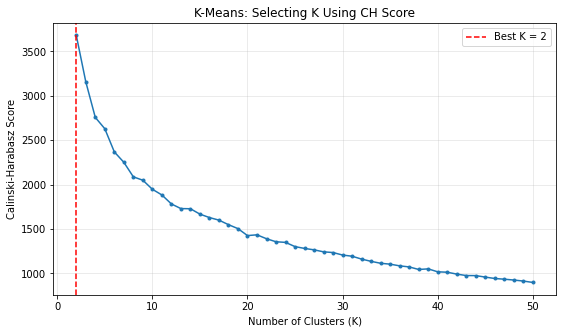

In [35]:

# Question 2(a): Select the best K using CH Score

from sklearn.cluster import KMeans
from sklearn.metrics import calinski_harabasz_score

k_values = range(2, 51)
ch_scores = []

for k in k_values:
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=3
    )

    cluster_labels = kmeans.fit_predict(X_cluster)

    score = calinski_harabasz_score(
        X_cluster, cluster_labels
    )

    ch_scores.append(score)

# Find the best K
best_k = list(k_values)[np.argmax(ch_scores)]

print("Best K:", best_k)
print("Best CH Score:", round(max(ch_scores), 4))

# Plot CH scores
plt.figure(figsize=(9, 5))
plt.plot(list(k_values), ch_scores, marker="o", markersize=3)
plt.axvline(best_k, color="red", linestyle="--",
            label=f"Best K = {best_k}")

plt.xlabel("Number of Clusters (K)")
plt.ylabel("Calinski-Harabasz Score")
plt.title("K-Means: Selecting K Using CH Score")
plt.legend()
plt.grid(alpha=0.3)
plt.show()


### (b) Determine which family is the majority

In [36]:

# Question 2(b): Find majority labels in each cluster

# Fit K-Means with the selected K
kmeans_best = KMeans(
    n_clusters=best_k,
    random_state=42,
    n_init=3
)

cluster_ids = kmeans_best.fit_predict(X_cluster)

# Combine cluster assignments with true labels
cluster_result = y_cluster.copy()
cluster_result["Cluster"] = cluster_ids

# Count observations in each cluster
cluster_sizes = cluster_result["Cluster"].value_counts().sort_index()

# Find the majority label for each cluster
majority_labels = cluster_result.groupby("Cluster")[
    ["Family", "Genus", "Species"]
].agg(lambda col: col.value_counts().idxmax())

print("Cluster sizes:")
print(cluster_sizes)

print("\nMajority labels for each cluster:")
display(majority_labels)


Cluster sizes:
0    3597
1    3598
Name: Cluster, dtype: int64

Majority labels for each cluster:


,Family,Genus,Species
Cluster,,,
0,Hylidae,Hypsiboas,HypsiboasCordobae
1,Leptodactylidae,Adenomera,AdenomeraHylaedactylus


### (c) Calculate the average Hamming distance, Hamming score, and Hamming loss

In [37]:

# Question 2(c): Calculate Hamming metrics

label_cols = ["Family", "Genus", "Species"]

# Assign majority labels to each observation
cluster_pred = pd.DataFrame({
    col: cluster_result["Cluster"].map(majority_labels[col])
    for col in label_cols
})

# Compare predicted labels with true labels
errors = (y_cluster[label_cols] != cluster_pred)

# Calculate Hamming metrics
avg_hamming_distance = errors.sum(axis=1).mean()
hamming_loss = errors.to_numpy().mean()
hamming_score = 1 - hamming_loss

print("Average Hamming Distance:",
      round(avg_hamming_distance, 4))
print("Hamming Score:", round(hamming_score, 4))
print("Hamming Loss:", round(hamming_loss, 4))


Average Hamming Distance: 0.8956
Hamming Score: 0.7015
Hamming Loss: 0.2985


In [38]:

# Question 2: 50 Monte Carlo simulations

X_array = X_cluster.to_numpy()
y_array = y_cluster[label_cols].to_numpy()

mc_results = []

for run in range(50):
    best_score = -np.inf
    best_clusters = None
    selected_k = None

    # Select K using CH score
    for k in range(2, 51):
        model = KMeans(
            n_clusters=k,
            random_state=42 + run,
            n_init=1,
            max_iter=150
        )

        clusters = model.fit_predict(X_array)
        score = calinski_harabasz_score(X_array, clusters)

        if score > best_score:
            best_score = score
            best_clusters = clusters
            selected_k = k

    # Assign majority labels within each cluster
    predictions = np.empty_like(y_array)

    for cluster in range(selected_k):
        mask = (best_clusters == cluster)

        for j in range(3):
            values, counts = np.unique(
                y_array[mask, j],
                return_counts=True
            )
            majority = values[np.argmax(counts)]
            predictions[mask, j] = majority

    # Calculate Hamming metrics
    errors = (y_array != predictions)
    distance = errors.sum(axis=1).mean()
    loss = errors.mean()
    score = 1 - loss

    mc_results.append({
        "K": selected_k,
        "Hamming Distance": distance,
        "Hamming Score": score,
        "Hamming Loss": loss
    })

    if (run + 1) % 5 == 0:
        print(f"Completed {run + 1}/50 simulations")

# Summarize all 50 simulations
mc_df = pd.DataFrame(mc_results)

print("\nSelected K counts:")
print(mc_df["K"].value_counts().sort_index())

print("\nMonte Carlo Results:")
print("Mean Hamming Distance:",
      round(mc_df["Hamming Distance"].mean(), 4))
print("Std Hamming Distance:",
      round(mc_df["Hamming Distance"].std(), 4))
print("Mean Hamming Score:",
      round(mc_df["Hamming Score"].mean(), 4))
print("Mean Hamming Loss:",
      round(mc_df["Hamming Loss"].mean(), 4))


Completed 5/50 simulations
Completed 10/50 simulations
Completed 15/50 simulations
Completed 20/50 simulations
Completed 25/50 simulations
Completed 30/50 simulations
Completed 35/50 simulations
Completed 40/50 simulations
Completed 45/50 simulations
Completed 50/50 simulations

Selected K counts:
2    50
Name: K, dtype: int64

Monte Carlo Results:
Mean Hamming Distance: 0.8956
Std Hamming Distance: 0.0
Mean Hamming Score: 0.7015
Mean Hamming Loss: 0.2985



### Question 2: K-Means Clustering

**(a) K-Means Clustering**

I applied K-Means clustering to the entire Anuran Calls dataset. I did not split the data into training and test sets because this is an unsupervised learning problem.

I used the Calinski-Harabasz (CH) Score to automatically select the number of clusters from K = 2 to K = 50. K = 1 was excluded because the CH Score is not defined for a single cluster.

In the initial experiment, the best K was 2, with a CH Score of 3680.7413.

**(b) Majority Labels**

For each cluster, I found the most frequent Family, Genus, and Species labels separately.

| Cluster | Size | Majority Family | Majority Genus | Majority Species |
|---|---:|---|---|---|
| 0 | 3597 | Hylidae | Hypsiboas | HypsiboasCordobae |
| 1 | 3598 | Leptodactylidae | Adenomera | AdenomeraHylaedactylus |

I assigned each observation the majority label triplet of its cluster.

**(c) Hamming Metrics and Monte Carlo Simulation**

I compared the assigned cluster labels with the true labels.

Hamming Distance counts the number of incorrect labels for each observation. Hamming Loss is the proportion of incorrect labels. Hamming Score is the proportion of correct labels.

Since each observation has three labels:

$$
\text{Hamming Loss} = \frac{\text{Average Hamming Distance}}{3}
$$

$$
\text{Hamming Score} = 1 - \text{Hamming Loss}
$$

I repeated the K-Means experiment 50 times using different random seeds. In each simulation, I selected K using the CH Score, determined the majority labels for each cluster, and calculated the Hamming metrics.

The results were:

| Metric | Result |
|---|---:|
| Number of simulations | 50 |
| Selected K | 2 in all 50 runs |
| Mean Hamming Distance | 0.8956 |
| Standard Deviation of Hamming Distance | 0.0000 |
| Mean Hamming Score | 0.7015 |
| Mean Hamming Loss | 0.2985 |

**Conclusion:**

The CH method selected two clusters in all 50 simulations. The Hamming Distance was the same across the simulations, resulting in a standard deviation of zero.

The Hamming Score of 0.7015 means that about 70.15% of the assigned labels were correct. K-Means provided a reasonable grouping of the observations. Its label prediction performance was much lower than that of the supervised SVM classifiers in Question 1.


## 3. ISLR 12.6.2

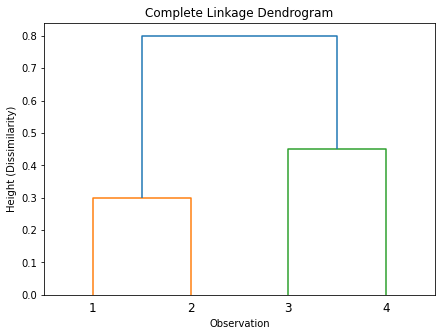

Linkage results:
[[0.   1.   0.3  2.  ]
 [2.   3.   0.45 2.  ]
 [4.   5.   0.8  4.  ]]


In [39]:

# Question 3(a): Complete linkage dendrogram

from scipy.cluster.hierarchy import linkage, dendrogram
from scipy.spatial.distance import squareform

# Dissimilarity matrix
dist_matrix = np.array([
    [0, 0.3, 0.4, 0.7],
    [0.3, 0, 0.5, 0.8],
    [0.4, 0.5, 0, 0.45],
    [0.7, 0.8, 0.45, 0]
])

# Complete linkage clustering
complete_linkage = linkage(
    squareform(dist_matrix),
    method="complete"
)

# Plot the dendrogram
plt.figure(figsize=(7, 5))
dendrogram(
    complete_linkage,
    labels=["1", "2", "3", "4"]
)

plt.title("Complete Linkage Dendrogram")
plt.xlabel("Observation")
plt.ylabel("Height (Dissimilarity)")
plt.show()

print("Linkage results:")
print(complete_linkage)



**(a) Complete Linkage**

Using complete linkage, the distance between two clusters is the maximum pairwise dissimilarity between their observations.

First, observations 1 and 2 merge at height 0.30.

Next, observations 3 and 4 merge at height 0.45.

Finally, the two clusters merge at height:

$$
\max(0.4, 0.7, 0.5, 0.8) = 0.80
$$

Therefore, the final merging height is 0.80, as shown in the dendrogram.


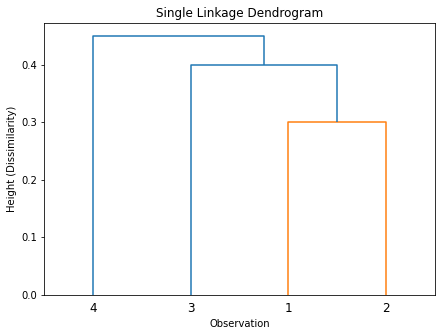

Linkage results:
[[0.   1.   0.3  2.  ]
 [2.   4.   0.4  3.  ]
 [3.   5.   0.45 4.  ]]


In [40]:

# Question 3(b): Single linkage dendrogram

# Single linkage clustering
single_linkage = linkage(
    squareform(dist_matrix),
    method="single"
)

# Plot the dendrogram
plt.figure(figsize=(7, 5))

dendrogram(
    single_linkage,
    labels=["1", "2", "3", "4"]
)

plt.title("Single Linkage Dendrogram")
plt.xlabel("Observation")
plt.ylabel("Height (Dissimilarity)")
plt.show()

print("Linkage results:")
print(single_linkage)



**(b) Single Linkage**

Using single linkage, the distance between two clusters is the minimum pairwise dissimilarity between their observations.

First, observations 1 and 2 merge at height 0.30.

Next, observation 3 joins cluster {1, 2} at height:

$$
\min(0.4, 0.5) = 0.40
$$

Finally, observation 4 joins cluster {1, 2, 3} at height:

$$
\min(0.7, 0.8, 0.45) = 0.45
$$

Therefore, the final merging height is 0.45, as shown in the dendrogram.



**(c) Complete Linkage with Two Clusters**

If we cut the complete linkage dendrogram at a height between 0.45 and 0.80, we obtain two clusters:

- Cluster 1: {1, 2}
- Cluster 2: {3, 4}

This is because the observations within each cluster have already merged, while the two clusters do not merge until height 0.80.


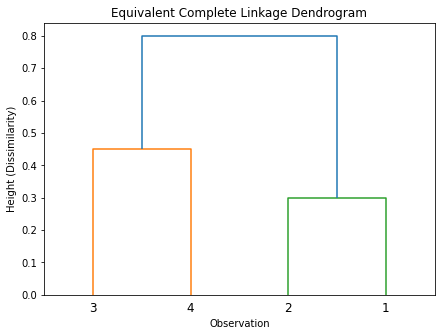

In [42]:

# Question 3(e): Equivalent complete linkage dendrogram

# Swap the left and right branches
flipped_linkage = complete_linkage.copy()

flipped_linkage[0, :2] = flipped_linkage[0, :2][::-1]
flipped_linkage[2, :2] = flipped_linkage[2, :2][::-1]

plt.figure(figsize=(7, 5))

dendrogram(
    flipped_linkage,
    labels=["1", "2", "3", "4"]
)

plt.title("Equivalent Complete Linkage Dendrogram")
plt.xlabel("Observation")
plt.ylabel("Height (Dissimilarity)")
plt.show()



**(d) Single Linkage with Two Clusters**

Cutting the single linkage dendrogram at a height between 0.40 and 0.45 gives:

- Cluster 1: {1, 2, 3}
- Cluster 2: {4}

Observations 1, 2, and 3 have already merged, while observation 4 does not join until height 0.45.

**(e) Equivalent Dendrogram**

I drew an equivalent complete linkage dendrogram by swapping the positions of branches.

The new leaf order is 3, 4, 2, 1 instead of 1, 2, 3, 4.

The merging relationships remain unchanged:

- Observations 1 and 2 merge at height 0.30.
- Observations 3 and 4 merge at height 0.45.
- Clusters {1,2} and {3,4} merge at height 0.80.

Changing the horizontal order of the branches does not change the clustering structure or the merging heights.

Therefore, the new dendrogram is equivalent to the original complete linkage dendrogram.
